# 5. A DSP that is only informed about the OSI CPI interface

## Producer: any vendor's signal generator

In [16]:
from osi_hfss import pipeline

for name in ("front", "corner"):
    files = [n for n in pipeline.names() if n.startswith(f"{name}.")]
    print(f"{name}: inputs {[n for n in files if pipeline.is_input(n)]}")
    print(f"{' ' * len(name)}  built by the modules {[n for n in files if not pipeline.is_input(n)]}")

front: inputs ['front.antenna.json', 'front.groundtruth.bin', 'front.scene.json', 'front.sensorviewconfiguration.bin', 'front.signal_generator.json']
       built by the modules ['front.antennamodel.bin', 'front.dsp.npz', 'front.generator_description.json', 'front.int16.radarcpidata.bin', 'front.phase_centre.sensordata.bin', 'front.radarcpidata.bin', 'front.raw.radarcpidata.bin', 'front.raw_noise_free.radarcpidata.bin', 'front.sensordata.bin', 'front.sensorview.bin']
corner: inputs ['corner.antenna.json', 'corner.groundtruth.bin', 'corner.scene.json', 'corner.sensorviewconfiguration.bin', 'corner.signal_generator.json']
        built by the modules ['corner.antennamodel.bin', 'corner.dsp.npz', 'corner.generator_description.json', 'corner.phase_centre.sensordata.bin', 'corner.pmcw.npz', 'corner.radarcpidata.bin', 'corner.raw.radarcpidata.bin', 'corner.sensordata.bin', 'corner.sensorview.bin']


## Consumer: the DSP, written against the OSI messages only

In [17]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import modules
from osi_hfss.analysis import closest, expected_positions
from osi_hfss.data import load
from osi_hfss.plots import format_spectrum_axes, plot_range_doppler, plot_spectrum

## The same function on both radars

The frames only differ in their metadata.

The DSP reads the `configuration_id` but never needs the configuration behind it.

In [18]:
radars = {}
for name in ("front", "corner"):
    cpi_data, antenna = load(f"{name}.radarcpidata.bin"), load(f"{name}.antennamodel.bin")  # the inputs
    sensor_data, analysis = modules.radar_dsp_with_analysis(cpi_data, antenna)  # + range-Doppler map, angle spectra
    ideal = modules.radar_dsp(cpi_data)  # no antenna model: ideal phase centres
    radars[name] = cpi_data, sensor_data, analysis, ideal
    frame = cpi_data.cpi_frame[0]
    feed = [(round(t.excitation_0.amplitude, 3), round(t.excitation_1.amplitude, 3)) for t in frame.transmitter]
    print(f"{name}: configuration_id {frame.configuration_id.value}, {len(frame.channel)} virtual channels, "
          f"{frame.slow_axis.size} x {frame.fast_axis.size} cells, {frame.center_frequency / 1e9:.2f} GHz")
    print(f"  rx_port {sorted({c.rx_port for c in frame.channel})}, Tx feed |(e_0, e_1)| {sorted(set(feed))}, "
          f"{sensor_data.feature_data.radar_sensor[0].header.number_of_valid_detections} detections")

front: configuration_id 1, 12 virtual channels, 64 x 256 cells, 76.75 GHz
  rx_port [0], Tx feed |(e_0, e_1)| [(1.0, 0.0)], 3 detections
corner: configuration_id 2, 16 virtual channels, 256 x 255 cells, 79.00 GHz
  rx_port [1], Tx feed |(e_0, e_1)| [(0.0, 1.0)], 5 detections


## Detections against the ground truth

front
 range [m] v_r [m/s] SNR [dB]  object   azimuth [deg]: antenna model, phase centres, truth
     22.13     16.95     48.5       3                         33.00          36.75  32.97
     56.91     -4.75     43.3       2                          5.50           6.25   5.56
     33.02      4.75     42.9       1                        -27.00         -30.00 -26.95

corner
 range [m] v_r [m/s] SNR [dB]  object   azimuth [deg]: antenna model, phase centres, truth
      9.14      7.25     79.4       1                        -21.75         -24.00 -21.80
      9.59      6.34     63.1       2                          3.00           3.25   2.97
     19.64      7.70     60.6       4                         32.00          35.75  32.03
     19.79      2.49     57.9       3                        -11.00         -12.00 -10.91
     22.03      7.70     31.4       5                        -31.75         -35.25 -31.60



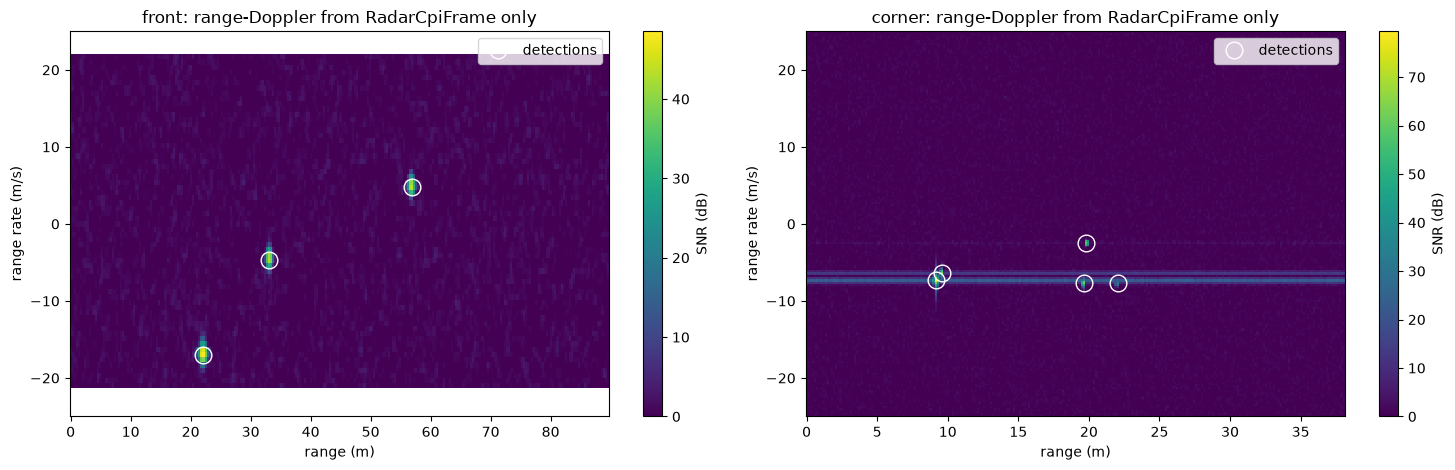

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (name, (cpi_data, sensor_data, analysis, ideal)) in zip(axes, radars.items()):
    expected = expected_positions(load(f"{name}.sensorview.bin"))
    print(f"{name}\n{'range [m]':>10} {'v_r [m/s]':>9} {'SNR [dB]':>8}  object   "
          f"azimuth [deg]: antenna model, phase centres, truth")
    for d, d_ideal in zip(sensor_data.feature_data.radar_sensor[0].detection, ideal.feature_data.radar_sensor[0].detection):
        e = closest(d, expected)
        print(f"{d.position.distance:10.2f} {d.radial_velocity:9.2f} {d.snr:8.1f}  {e.object_id:6d}   "
              f"{np.degrees(d.position.azimuth):27.2f} {np.degrees(d_ideal.position.azimuth):14.2f} "
              f"{np.degrees(e.azimuth):6.2f}")
    print()

    plot_range_doppler(analysis["range"], analysis["range_rate"], analysis["snr"], sensor_data, ax=ax,
                       ylim=(-25, 25), title=f"{name}: range-Doppler from RadarCpiFrame only")
plt.tight_layout(); plt.show()

## DOA spectra: phase centres vs. antenna model

The Bartlett spectrum of the strongest detection of each radar, with the steering vectors from the ideal phase centres and from the antenna model.

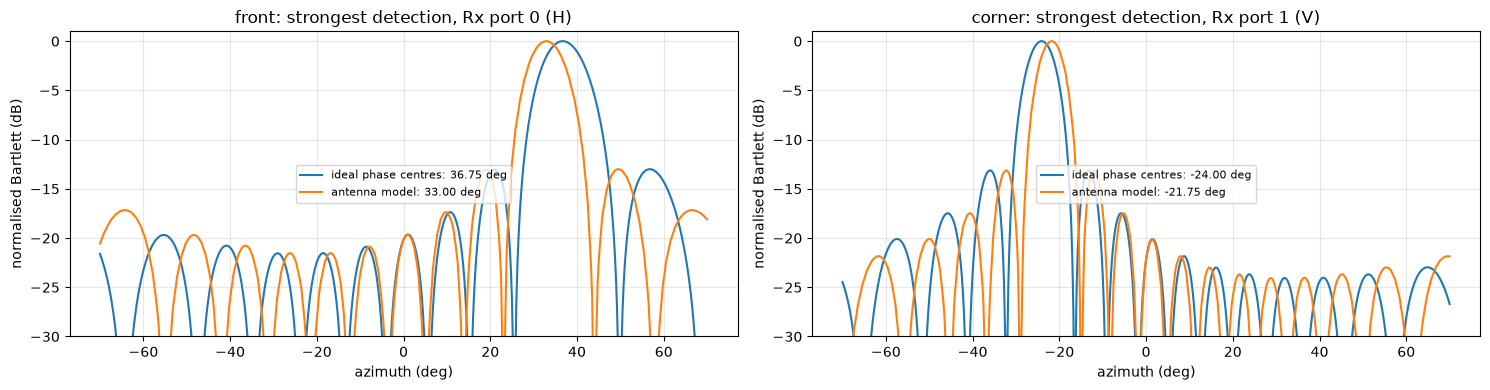

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (name, (cpi_data, _, analysis, _)) in zip(axes, radars.items()):
    frame, azimuth = cpi_data.cpi_frame[0], analysis["azimuth"]
    for key, label in (("spectrum_phase_centre", "ideal phase centres"), ("spectrum_antenna", "antenna model")):
        p = analysis[key][0]  # detections are sorted by SNR: the first is the strongest
        plot_spectrum(ax, azimuth, p, label=f"{label}: {np.degrees(azimuth[np.argmax(p)]):.2f} deg")
    port = frame.channel[0].rx_port
    format_spectrum_axes(ax, f"{name}: strongest detection, Rx port {port} ({'HV'[port]})", ncol=1)
plt.tight_layout(); plt.show()